In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/adult.csv",na_values=["?"],skipinitialspace=True)

In [ ]:
df_original = df.copy()

<h1>data understanding</h1>

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [ ]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [ ]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
df.shape

(32561, 15)

In [ ]:
df.duplicated().sum()

np.int64(24)

In [ ]:
df.select_dtypes(int)

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,90,77053,9,0,4356,40
1,82,132870,9,0,4356,18
2,66,186061,10,0,4356,40
3,54,140359,4,0,3900,40
4,41,264663,10,0,3900,40
...,...,...,...,...,...,...
32556,22,310152,10,0,0,40
32557,27,257302,12,0,0,38
32558,40,154374,9,0,0,40
32559,58,151910,9,0,0,40


<Axes: ylabel='age'>

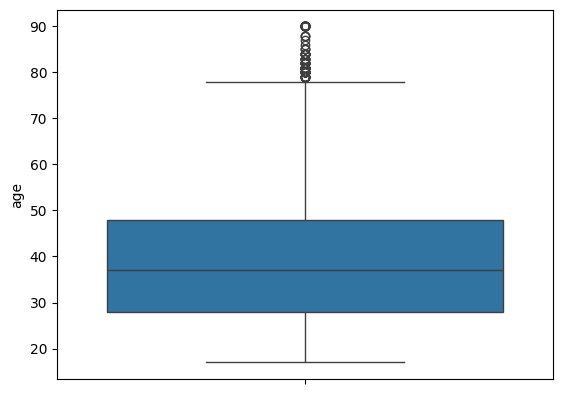

In [ ]:
sns.boxplot(df['age'])

<Axes: xlabel='age', ylabel='Count'>

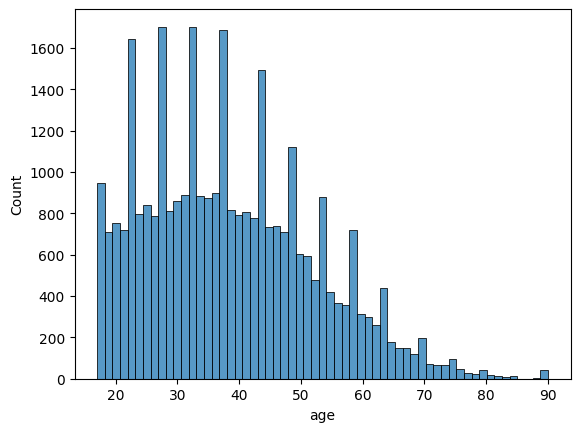

In [ ]:
sns.histplot(df['age'])

### Outlier Detection and Distribution Analysis – Age

A box plot was used to identify potential outliers in the `age` column using the Interquartile Range (IQR) method.

The median age is approximately 35 years, while Q1 and Q3 are approximately 30 and 50 years, respectively. The box plot indicates some observations beyond the upper whisker, particularly at higher ages.

A histogram was also plotted to understand the distribution of age. The histogram shows a positively skewed (right-skewed) distribution, indicating that most observations are concentrated at lower and middle ages, with a longer tail towards higher ages.

The detected outliers will not be removed immediately because higher age values may represent valid observations. Their treatment will be decided after further investigation.

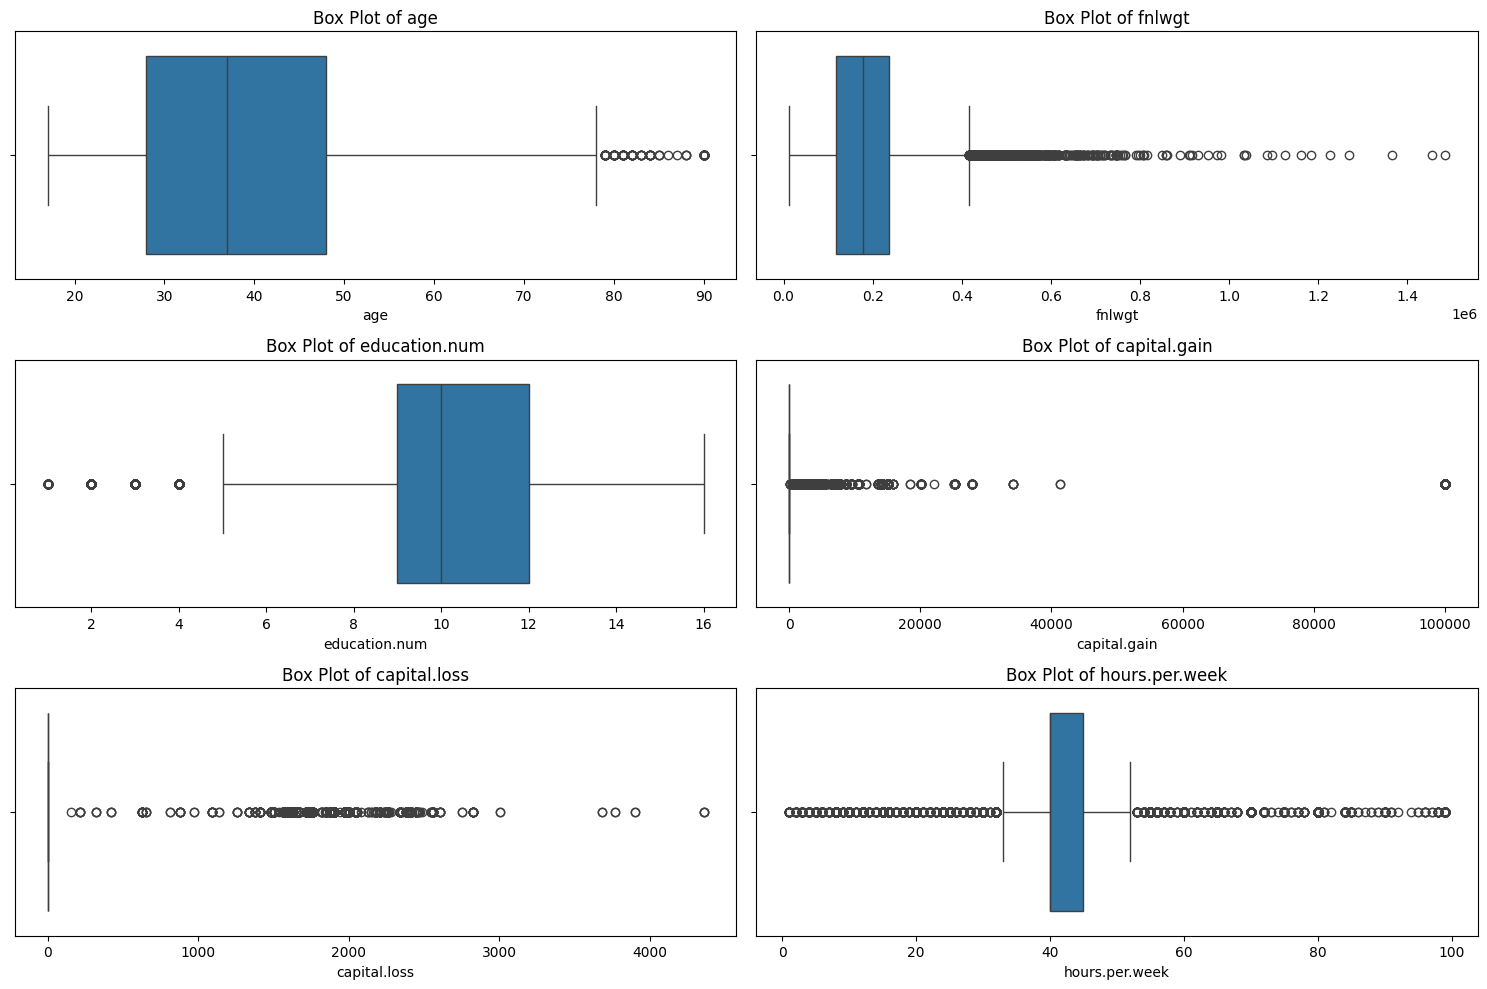

In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

In [ ]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"\nColumn: {col}")
    print("Lower Fence:", lower)
    print("Upper Fence:", upper)
    print("Outlier Count:", len(outliers))


Column: age
Lower Fence: -2.0
Upper Fence: 78.0
Outlier Count: 143

Column: fnlwgt
Lower Fence: -61009.0
Upper Fence: 415887.0
Outlier Count: 992

Column: education.num
Lower Fence: 4.5
Upper Fence: 16.5
Outlier Count: 1198

Column: capital.gain
Lower Fence: 0.0
Upper Fence: 0.0
Outlier Count: 2712

Column: capital.loss
Lower Fence: 0.0
Upper Fence: 0.0
Outlier Count: 1519

Column: hours.per.week
Lower Fence: 32.5
Upper Fence: 52.5
Outlier Count: 9008


### Statistical Outlier Detection Using IQR

The Interquartile Range (IQR) method was applied to all numerical columns to identify potential outliers.

The analysis identified 143 outliers in age, 992 in fnlwgt, 1,198 in education-num, 2,712 in capital-gain, 1,519 in capital-loss, and 9,008 in hours-per-week.

The capital-gain and capital-loss columns had an IQR of zero because at least 75% of their observations were zero. Therefore, positive values were flagged as potential outliers.

The hours-per-week column also showed a relatively high number of observations outside the IQR boundaries.

These values were not automatically removed because statistical outliers may represent genuine observations. Further investigation is required before deciding on any treatment.

<h1>EDA</h1>

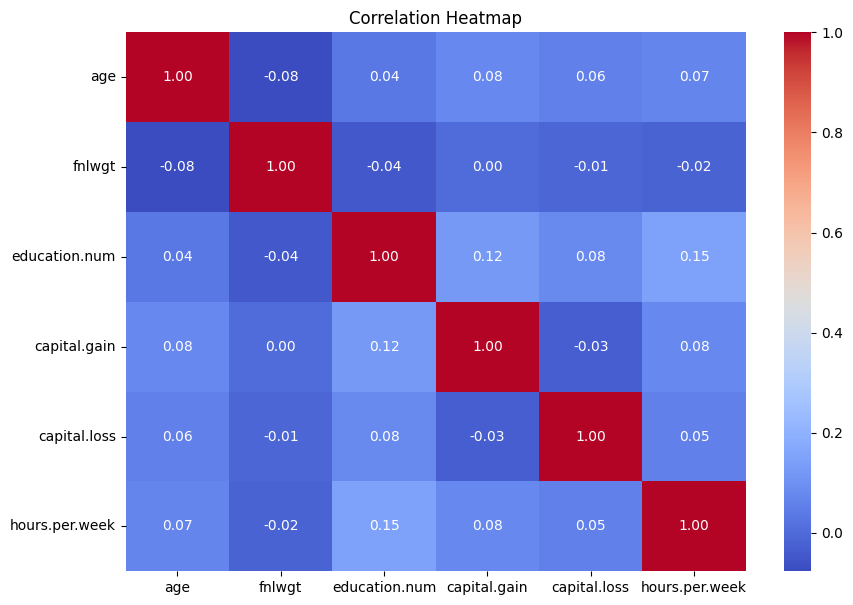

In [ ]:
numeric_df = df.select_dtypes(include=['number'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

The correlation heatmap shows that all numerical features have very weak correlations with each other. The highest positive correlation is between education.num and hours.per.week (0.15), while the strongest negative correlation is between age and fnlwgt (−0.08). Therefore, there are no strong linear relationships among the numerical features.

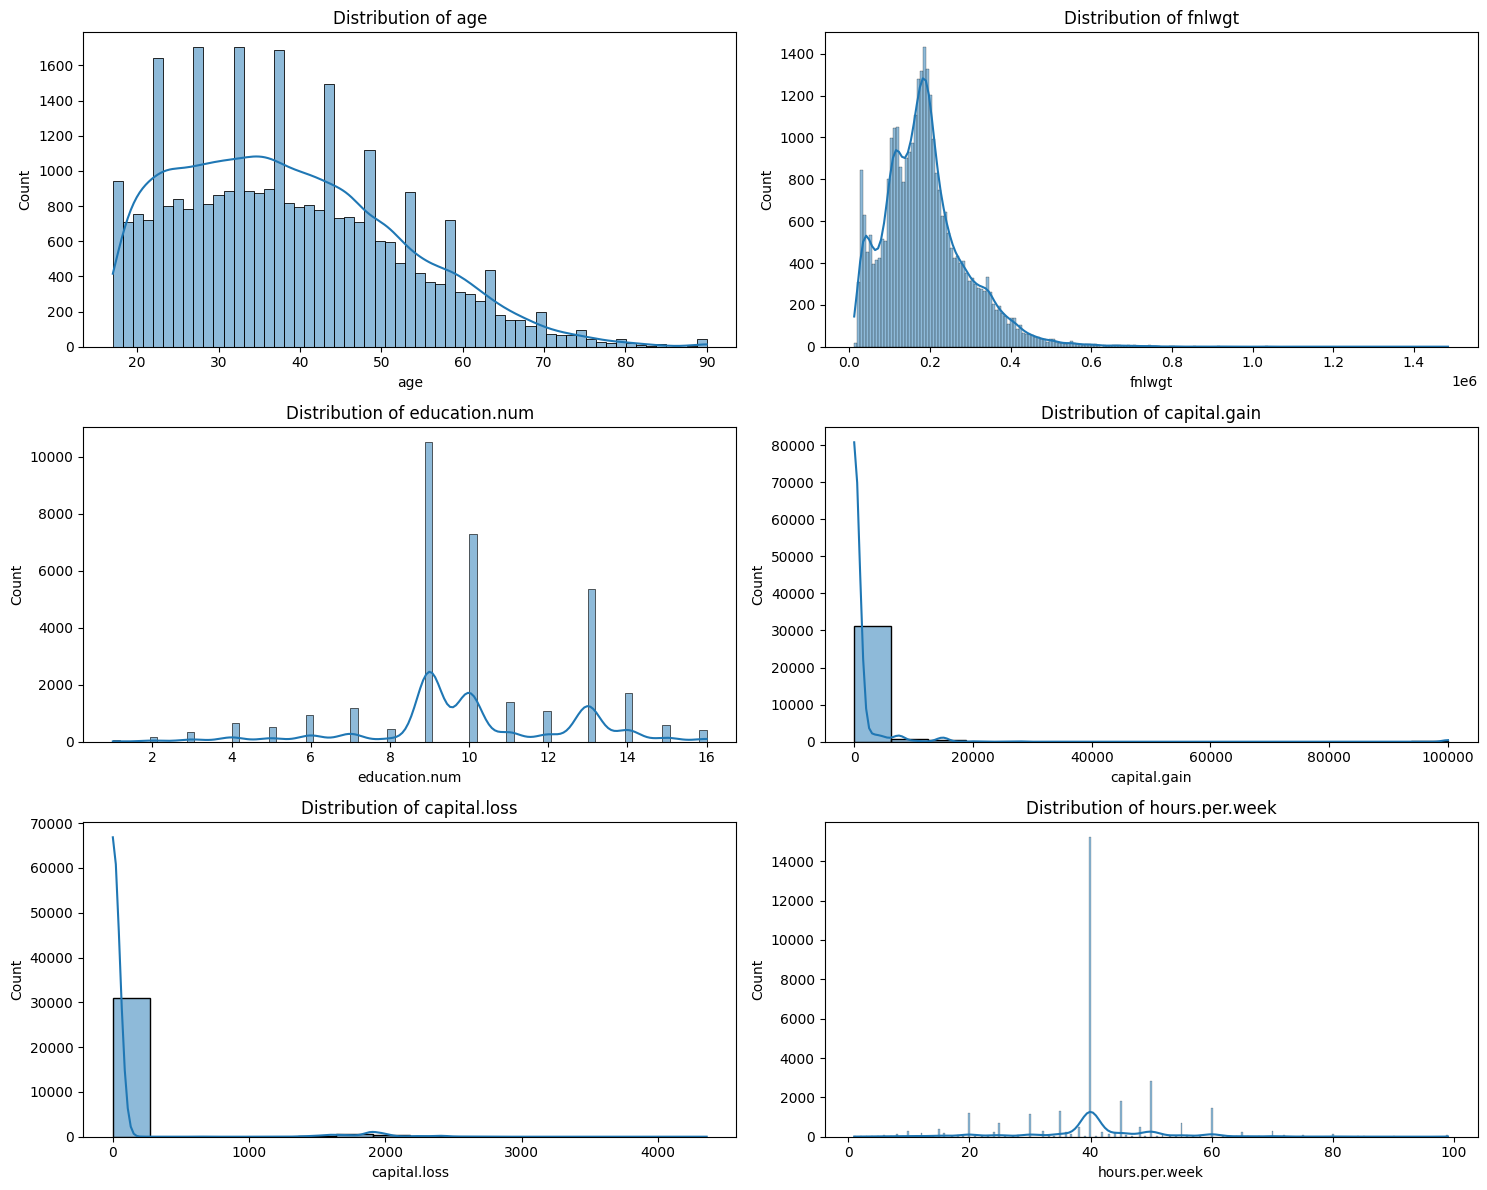

In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

here the feautres like age , capital gain , capital loss , fnlgwt has the right skewed data , whereas hours per week , education.num has normal distributed data

In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns

<h1>Handling missing values </h1>

In [ ]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [ ]:
df['workclass']=df['workclass'].fillna(df['workclass'].mode()[0])
df['occupation']=df['occupation'].fillna(df['occupation'].mode()[0])
df['native.country']=df['native.country'].fillna(df['native.country'].mode()[0])

In [ ]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


<h1>Categorical encoding</h1>

In [ ]:
string_cols = df.select_dtypes(include=['object']).columns
print(string_cols)

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

for col in string_cols:
    df[col] = label_encoder.fit_transform(df[col])

<h1>Handling outliers</h1>

In [ ]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

In [ ]:
df.to_csv("adult_cleaned.csv", index=False)

In [ ]:
print(df.shape)
print(df.isnull().sum())
print(df.head())

(32561, 15)
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64
        age  workclass    fnlwgt  education  education.num  marital.status  \
0  3.769612  -0.085296 -1.067997   0.181332      -0.420060        2.249480   
1  3.183112  -0.085296 -0.539169   0.181332      -0.420060        2.249480   
2  2.010110  -0.085296 -0.035220   1.214869      -0.031360        2.249480   
3  1.130359  -0.085296 -0.468215  -1.368974      -2.363558       -1.734058   
4  0.177296  -0.085296  0.709482   1.214869      -0.031360        1.585557   

   occupation  relationship      race       sex  capital.gain  capital.loss  \
0    0.720237     -0.277805  0.393668 -1.422331      -0.14592     10.593507   
1   -0.790092     -0.277805  0.393668 -1.422331 